# analysis_00: code checks of the reward and of the emotion observation

This notebook runs no training and loads no CSV. It calls the shipped code (`agent_policies_gt_ais`,
`env_gt_ais`, `main_gt_ais`) on controlled inputs and checks that it does what the model specifies. Every
check is collected in the table of section 4.

The journal model is the `homeostatic_signed` scheme (`REWARD_SCHEME` in `main_gt_ais`). The
`homeostatic` and `legacy_ais2026` schemes are checked next to it as references.

**Contents**

1. Setup
2. Reward
3. Observation
4. Check summary
5. Modelling notes

## 1. Setup

In [1]:
import sys
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy import stats
from IPython.display import display

from analysis_utils import CAT, INK, ORDINAL_BLUE as BLUE_RAMP, SURFACE, apply_house_style

# import the experiment code itself: every formula and constant below comes from
# the modules the runs use, never from a copy pasted here.
REPO = Path("..").resolve()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from agent_policies_gt_ais import (Agent, SocialRewardCalculator,          # noqa: E402
                                   perceive_bounded, precision_to_concentration)
from env_gt_ais import GameTheoreticEnv                                    # noqa: E402
from main_gt_ais import (NB_AGENTS, BETA, THRESHOLD, SMOOTHING,            # noqa: E402
                         SIGMOID_GAIN, EMOTION_DECIMALS, REWARD_SCHEME,
                         make_condition, init_env, set_global_seed)

MEMORY_SIZE = Agent(0).memory_size
ALPHAS = [0.0, 0.25, 0.5, 0.75, 0.99]       # the exp3 grid
SCHEMES = ["legacy_ais2026", "homeostatic", "homeostatic_signed"]
SEED = 0

CHECKS = []   # (section, check, passed), summarised in section 4


def check(section, name, passed):
    CHECKS.append((section, name, bool(passed)))
    print(("PASS  " if passed else "FAIL  ") + name)


print(f"code          : {REPO}")
print(f"default scheme: {REWARD_SCHEME}")
print(f"N = {NB_AGENTS}, memory = {MEMORY_SIZE}, beta = {BETA}, threshold = {THRESHOLD}, "
      f"smoothing = {SMOOTHING}, emotion decimals = {EMOTION_DECIMALS}")

code          : C:\Users\evann\OneDrive\Documents\1.neuro\ISIR\03_GT
default scheme: homeostatic_signed
N = 6, memory = 10, beta = 0.5, threshold = 0.5, smoothing = linear, emotion decimals = 2


In [2]:
apply_house_style()

# the journal scheme in blue, the two references in recessive colours
SCHEME_COLOR = {"homeostatic_signed": CAT[0], "homeostatic": CAT[2], "legacy_ais2026": INK["muted"]}
SCHEME_LABEL = {"homeostatic_signed": "signed homeostatic (journal)",
                "homeostatic": "homeostatic, empathic term on [0, 1]",
                "legacy_ais2026": "legacy (AIS 2026)"}
ORDINAL_BLUE = ["#c3dcf8"] + BLUE_RAMP

# reward crosses zero in the signed and legacy schemes: diverging map pinned at 0
REWARD_CMAP = LinearSegmentedColormap.from_list(
    "reward", ["#a8360d", "#eb6834", "#f6b79b", SURFACE, "#8fbcf1", "#2a78d6", "#0f3f7d"])
REWARD_NORM = TwoSlopeNorm(vmin=-1.0, vcenter=0.0, vmax=1.0)

In [3]:
# helpers: populations of REAL Agent objects whose memory is set through the real
# record_meal() path, scored by the REAL SocialRewardCalculator.

def make_calc(scheme, alpha):
    return SocialRewardCalculator(NB_AGENTS, alpha=alpha, beta=BETA, threshold=THRESHOLD,
                                  smoothing=SMOOTHING, sigmoid_gain=SIGMOID_GAIN,
                                  reward_scheme=scheme)


def agent_with(window_before, meal):
    """agent whose memory window is `window_before`, then records `meal` this step."""
    a = Agent(0, memory_size=MEMORY_SIZE)
    for m in window_before:
        a.record_meal(bool(m))
    a.record_meal(bool(meal))
    return a


def agent_from_window(window):
    """agent whose memory window is exactly `window` (MEMORY_SIZE recorded steps)."""
    assert len(window) == MEMORY_SIZE
    a = Agent(0, memory_size=MEMORY_SIZE)
    for m in window:
        a.record_meal(bool(m))
    return a


def others_at_rate(k):
    """N-1 agents with exactly k meals in their window (emotion of rate k/10)."""
    return [agent_from_window([1] * k + [0] * (MEMORY_SIZE - k))
            for _ in range(NB_AGENTS - 1)]

## 2. Reward

Let $h_i(t^-)\in[0,1]$ be agent $i$'s satiety, the share of meals in its 10-step memory **before**
the current step, $m_i(t)\in\{0,1\}$ the current meal and $\bar e_{-i}\in[-1,1]$ the mean emotion
of the others. The three schemes all compute $r_i=(1-\alpha_i)\,p_i+\alpha_i\,\varepsilon_i$ and
differ by the two terms:

| scheme | personal term $p_i$ | empathic term $\varepsilon_i$ | reward interval |
|---|---|---|---|
| `homeostatic_signed` (journal model) | $m_i(t)\,(1-h_i(t^-))$ | $\bar e_{-i}\in[-1,1]$ | $[-\alpha_i, 1]$ |
| `homeostatic` | $m_i(t)\,(1-h_i(t^-))$ | $(\bar e_{-i}+1)/2\in[0,1]$ | $[0, 1]$ |
| `legacy_ais2026` (AIS paper) | $\beta\,\text{last}+(1-\beta)\,\text{hist}$ | $\bar e_{-i}\in[-1,1]$ | $[-\alpha_i, 1]$ |

In the two homeostatic schemes only meals feed the personal term (abstaining scores 0), and a meal
is worth more the hungrier the agent is.

### 2.1 Bounds: exhaustive enumeration

Agent 0 takes **every** possible 10-step window before the step ($2^{10}$) × both
outcomes of the current step; the five others hold every consumption rate
$k/10$, $k=0\dots10$ (so the others' mean emotion covers $[-1,1]$, extremes included).
That is $2^{11}\times 11$ populations per scheme and per α, each scored by the shipped
calculator.

In [4]:
other_pops = [others_at_rate(k) for k in range(MEMORY_SIZE + 1)]
windows = [[(w >> b) & 1 for b in range(MEMORY_SIZE)] for w in range(2 ** MEMORY_SIZE)]

rows = []
calcs = {(s, a): make_calc(s, a) for s in SCHEMES for a in ALPHAS}
for w in windows:
    for meal in (0, 1):
        me = agent_with(w, meal)
        for pop_id, others in enumerate(other_pops):
            pop = [me] + others
            for s in SCHEMES:
                for a in ALPHAS:
                    _, pers, emp, tot = calcs[(s, a)].calculate_rewards(pop)
                    rows.append((s, a, sum(w) / MEMORY_SIZE, meal, pop_id,
                                 pers[0], emp[0], tot[0]))
enum = pd.DataFrame(rows, columns=["scheme", "alpha", "h_before", "meal", "others",
                                   "personal", "empathic", "reward"])
print(f"{len(enum):,} (scheme, alpha, population) evaluations")

bounds = (enum.groupby(["scheme", "alpha"])
              .agg(personal_min=("personal", "min"), personal_max=("personal", "max"),
                   empathic_min=("empathic", "min"), empathic_max=("empathic", "max"),
                   reward_min=("reward", "min"), reward_max=("reward", "max"))
              .round(6))
display(bounds)

337,920 (scheme, alpha, population) evaluations


personal_min  personal_max  empathic_min  \
scheme             alpha                                             
homeostatic        0.00            0.0           1.0           0.0   
                   0.25            0.0           1.0           0.0   
                   0.50            0.0           1.0           0.0   
                   0.75            0.0           1.0           0.0   
                   0.99            0.0           1.0           0.0   
homeostatic_signed 0.00            0.0           1.0          -1.0   
                   0.25            0.0           1.0          -1.0   
                   0.50            0.0           1.0          -1.0   
                   0.75            0.0           1.0          -1.0   
                   0.99            0.0           1.0          -1.0   
legacy_ais2026     0.00            0.0           1.0          -1.0   
                   0.25            0.0           1.0          -1.0   
                   0.50            0.0           1.0          -1.0   
                   0.75            0.0           1.0          -1.0   
                   0.99            0.0           1.0          -1.0   

                          empathic_max  reward_min  reward_max  
scheme             alpha                                        
homeostatic        0.00            1.0        0.00         1.0  
                   0.25            1.0        0.00         1.0  
                   0.50            1.0        0.00         1.0  
                   0.75            1.0        0.00         1.0  
                   0.99            1.0        0.00         1.0  
homeostatic_signed 0.00            1.0        0.00         1.0  
                   0.25            1.0       -0.25         1.0  
                   0.50            1.0       -0.50         1.0  
                   0.75            1.0       -0.75         1.0  
                   0.99            1.0       -0.99         1.0  
legacy_ais2026     0.00            1.0        0.00         1.0  
                   0.25            1.0       -0.25         1.0  
                   0.50            1.0       -0.50         1.0  
                   0.75            1.0       -0.75         1.0  
                   0.99            1.0       -0.99         1.0

In [5]:
h = enum[enum.scheme == "homeostatic"]
l = enum[enum.scheme == "legacy_ais2026"]
s = enum[enum.scheme == "homeostatic_signed"]
hb = bounds.loc["homeostatic"]
lb = bounds.loc["legacy_ais2026"]
sb = bounds.loc["homeostatic_signed"]

check("2.1 bounds", "signed: personal term spans [0, 1], empathic term spans [-1, 1]",
      s.personal.min() == 0 and s.personal.max() == 1
      and np.isclose(s.empathic.min(), -1) and np.isclose(s.empathic.max(), 1))
check("2.1 bounds", "signed: reward attains exactly [-alpha, 1] at EVERY alpha",
      np.allclose(sb.reward_min.values, -np.array(ALPHAS)) and np.allclose(sb.reward_max, 1))
check("2.1 bounds", "signed: empathic term == mean others' emotion, the scale of the observation",
      np.allclose(s.empathic.values, l.empathic.values)
      and make_calc("homeostatic_signed", 0.5).emotion_range == (-1.0, 1.0))
check("2.1 bounds", "homeostatic: personal and empathic terms both span exactly [0, 1]",
      h.personal.min() == 0 and h.personal.max() == 1
      and np.isclose(h.empathic.min(), 0) and np.isclose(h.empathic.max(), 1))
check("2.1 bounds", "homeostatic: reward attains exactly [0, 1] at EVERY alpha",
      np.allclose(hb.reward_min, 0) and np.allclose(hb.reward_max, 1))
check("2.1 bounds", "homeostatic: no negative reward anywhere",
      (h.reward >= 0).all())
check("2.1 bounds", "homeostatic: empathic term == (mean others' emotion + 1) / 2, "
      "the scale of the observation", np.allclose(h.empathic.values, (l.empathic.values + 1) / 2)
      and make_calc("homeostatic", 0.5).emotion_range == (0.0, 1.0))
check("2.1 bounds", "legacy: reward interval is [-alpha, 1]",
      np.allclose(lb.reward_min.values, -np.array(ALPHAS))
      and np.allclose(lb.reward_max, 1))
check("2.1 bounds", "total = (1 - alpha) * personal + alpha * empathic, all schemes",
      np.allclose(enum.reward, (1 - enum.alpha) * enum.personal + enum.alpha * enum.empathic))

PASS  signed: personal term spans [0, 1], empathic term spans [-1, 1]
PASS  signed: reward attains exactly [-alpha, 1] at EVERY alpha
PASS  signed: empathic term == mean others' emotion, the scale of the observation
PASS  homeostatic: personal and empathic terms both span exactly [0, 1]
PASS  homeostatic: reward attains exactly [0, 1] at EVERY alpha
PASS  homeostatic: no negative reward anywhere
PASS  homeostatic: empathic term == (mean others' emotion + 1) / 2, the scale of the observation
PASS  legacy: reward interval is [-alpha, 1]
PASS  total = (1 - alpha) * personal + alpha * empathic, all schemes


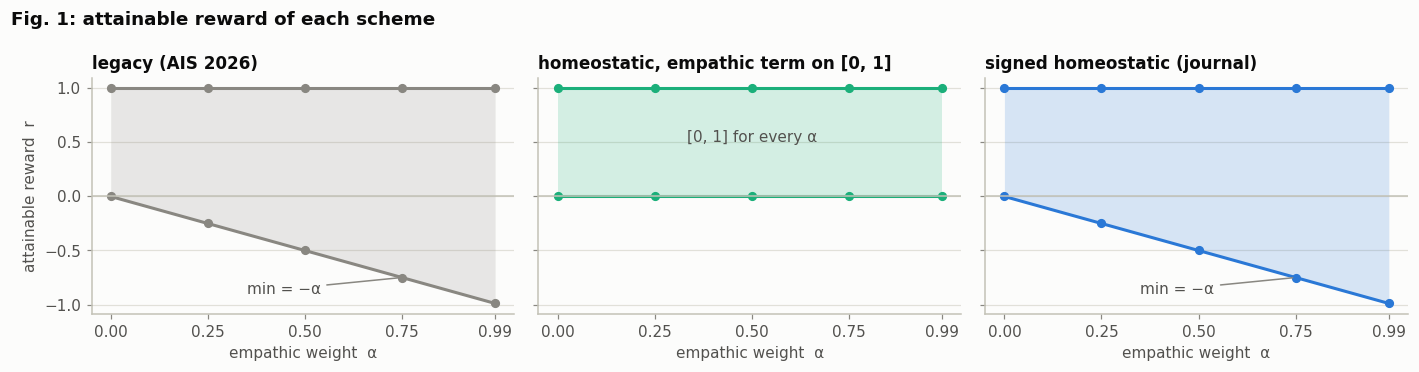

In [6]:
fig, axes = plt.subplots(1, len(SCHEMES), figsize=(13, 3.4), sharey=True)
for ax, s in zip(axes, SCHEMES):
    b = bounds.loc[s]
    ax.fill_between(ALPHAS, b.reward_min, b.reward_max, color=SCHEME_COLOR[s], alpha=0.18,
                    linewidth=0)
    ax.plot(ALPHAS, b.reward_max, color=SCHEME_COLOR[s], marker="o", ms=5)
    ax.plot(ALPHAS, b.reward_min, color=SCHEME_COLOR[s], marker="o", ms=5)
    ax.axhline(0, color=INK["baseline"], lw=1)
    ax.set_title(SCHEME_LABEL[s])
    ax.set_xlabel("empathic weight  α")
    ax.set_xticks(ALPHAS)
axes[0].set_ylabel("attainable reward  r")
for ax in (axes[0], axes[2]):
    ax.annotate("min = −α", (0.75, -0.75), xytext=(0.35, -0.9), color=INK["secondary"],
                arrowprops=dict(arrowstyle="-", color=INK["muted"]))
axes[1].annotate("[0, 1] for every α", (0.5, 0.5), ha="center", color=INK["secondary"])
fig.suptitle("Fig. 1: attainable reward of each scheme", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
plt.show()

### 2.2 Orientation: what one meal is worth, as a function of satiety

Same enumeration, read differently: the personal term when the agent **eats** at this
step, against its satiety just before. Homeostatic (both schemes share this term): exactly
$1-h$, strictly decreasing, and abstaining is worth exactly 0. Legacy: increasing, so the more an
agent has eaten, the more a meal pays (band = spread over windows with the same satiety,
because the legacy history term depends on which meal leaves the window).

PASS  signed: value of a meal = 1 - satiety before it (exact)
PASS  signed: value of a meal strictly decreasing in satiety
PASS  signed: abstaining yields personal term 0
PASS  homeostatic and signed share the same personal term


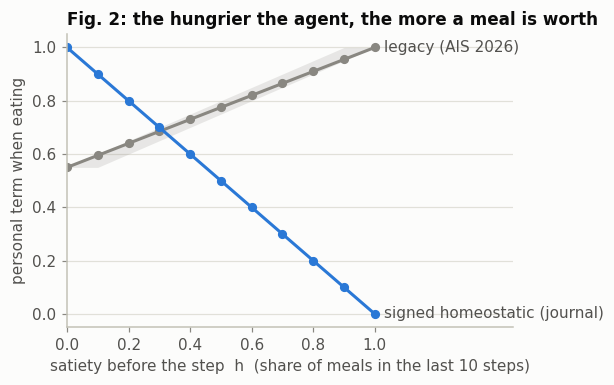

In [7]:
p_eat = (enum[(enum.alpha == 0) & (enum.others == 0) & (enum.meal == 1)]
         .groupby(["scheme", "h_before"]).personal.agg(["mean", "min", "max"]))
p_abs = enum[(enum.scheme == "homeostatic_signed") & (enum.meal == 0)].personal
hs = np.round(np.arange(MEMORY_SIZE + 1) / MEMORY_SIZE, 10)

ph = p_eat.loc["homeostatic_signed"]
check("2.2 orientation", "signed: value of a meal = 1 - satiety before it (exact)",
      np.allclose(ph["min"], 1 - ph.index) and np.allclose(ph["max"], 1 - ph.index))
check("2.2 orientation", "signed: value of a meal strictly decreasing in satiety",
      (np.diff(ph["mean"].values) < 0).all())
check("2.2 orientation", "signed: abstaining yields personal term 0", (p_abs == 0).all())
check("2.2 orientation", "homeostatic and signed share the same personal term",
      np.allclose(enum[enum.scheme == "homeostatic"].personal,
                  enum[enum.scheme == "homeostatic_signed"].personal))

SHOWN = ["legacy_ais2026", "homeostatic_signed"]     # the homeostatic curve is identical to the signed one
fig, ax = plt.subplots(figsize=(5.6, 3.6))
for s in SHOWN:
    d = p_eat.loc[s]
    ax.fill_between(d.index, d["min"], d["max"], color=SCHEME_COLOR[s], alpha=0.18, lw=0)
    ax.plot(d.index, d["mean"], color=SCHEME_COLOR[s], marker="o", ms=5)
    ax.annotate(SCHEME_LABEL[s], (d.index[-1], d["mean"].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK["secondary"])
ax.set_xlabel("satiety before the step  h  (share of meals in the last 10 steps)")
ax.set_ylabel("personal term when eating")
ax.set_xlim(0, 1.45)
ax.set_xticks(np.linspace(0, 1, 6))
ax.set_title("Fig. 2: the hungrier the agent, the more a meal is worth")
fig.tight_layout()
plt.show()

### 2.3 Consequence: a built-in optimal consumption rate

An agent that eats at a long-run rate $f$ (i.i.d. meals) has $E[h]=f$ independently of
the current meal, so its mean personal reward per step is
$E[m(1-h)] = f(1-f)$: maximal at $f = 0.5$, and **zero for an agent that eats at every
step**. The legacy personal term has mean $f$, so "always eat" is the selfish optimum.
Simulated below with the real `Agent` / calculator over 20 000 steps per rate.

PASS  signed: mean personal reward = f(1-f) (|err| < 0.015)
PASS  signed: optimum consumption rate is 0.5
PASS  legacy: mean personal reward = f (always-eat optimum, |err| < 0.015)


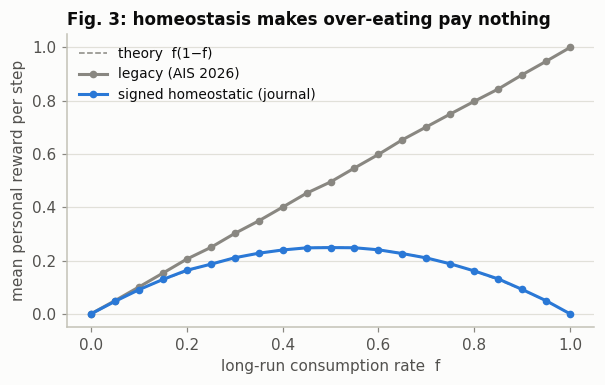

In [8]:
rng = np.random.default_rng(SEED)
rates = np.linspace(0, 1, 21)
n_steps = 20_000
others = others_at_rate(5)
steady = {s: [] for s in SCHEMES}
for f in rates:
    me = Agent(0, memory_size=MEMORY_SIZE)
    meals = rng.random(n_steps) < f
    acc = {s: 0.0 for s in SCHEMES}
    for m in meals:
        me.record_meal(bool(m))
        for s in SCHEMES:
            acc[s] += calcs[(s, 0.0)].calculate_rewards([me] + others)[1][0]
    for s in SCHEMES:
        steady[s].append(acc[s] / n_steps)
steady = pd.DataFrame(steady, index=rates)

check("2.3 steady state", "signed: mean personal reward = f(1-f) (|err| < 0.015)",
      np.abs(steady.homeostatic_signed - rates * (1 - rates)).max() < 0.015)
check("2.3 steady state", "signed: optimum consumption rate is 0.5",
      abs(steady.homeostatic_signed.idxmax() - 0.5) <= 0.05)
check("2.3 steady state", "legacy: mean personal reward = f (always-eat optimum, |err| < 0.015)",
      np.abs(steady.legacy_ais2026 - rates).max() < 0.015)

fig, ax = plt.subplots(figsize=(5.6, 3.6))
ff = np.linspace(0, 1, 200)
ax.plot(ff, ff * (1 - ff), color=INK["muted"], lw=1, ls="--", label="theory  f(1−f)")
for s in SHOWN:
    ax.plot(rates, steady[s], color=SCHEME_COLOR[s], marker="o", ms=4,
            label=SCHEME_LABEL[s])
ax.set_xlabel("long-run consumption rate  f")
ax.set_ylabel("mean personal reward per step")
ax.set_title("Fig. 3: homeostasis makes over-eating pay nothing")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

### 2.4 Reward maps for an agent that eats

Total reward of an **eating** agent, over its satiety (x) and the others' consumption
rate (y, which sets $\bar e_{-i}$), at three α. One diverging scale for every panel,
pinned at 0: in the legacy and signed schemes the empathic term can drive the reward negative as α
grows; in the `homeostatic` scheme every panel stays inside $[0,1]$.

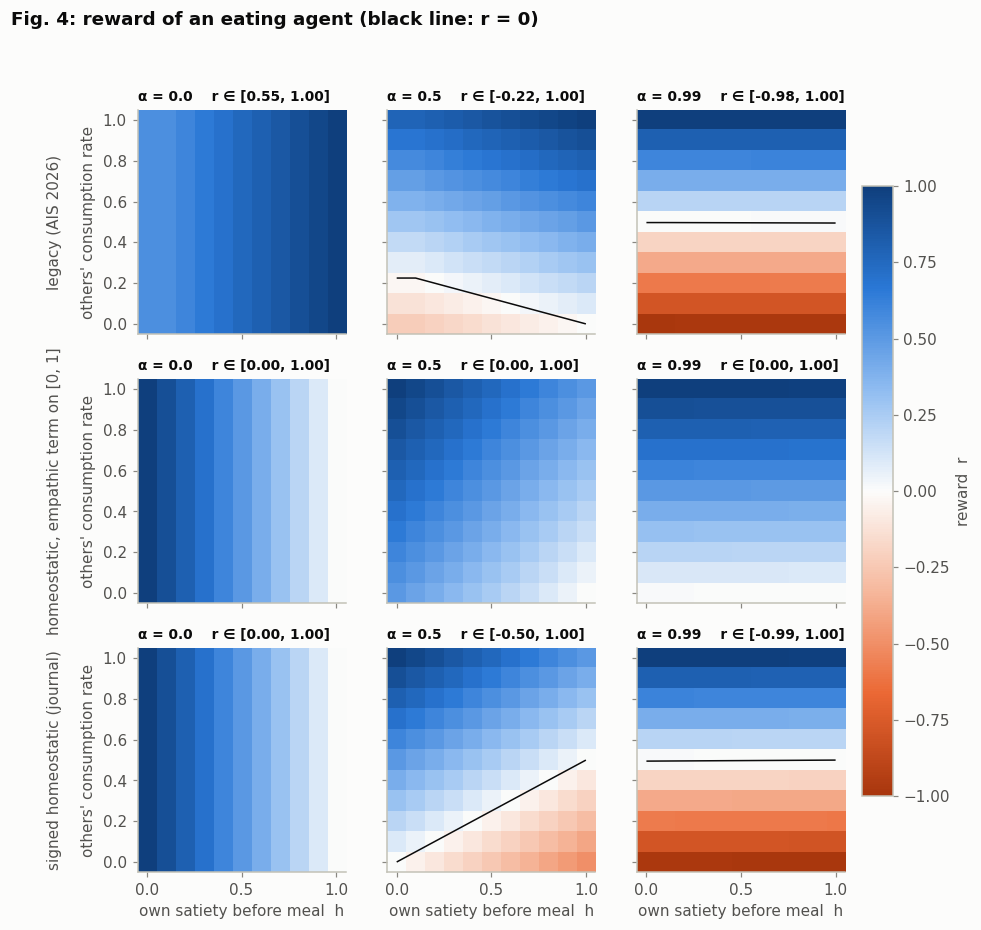

In [9]:
show_alphas = [0.0, 0.5, 0.99]
ks = np.arange(MEMORY_SIZE + 1)
fig, axes = plt.subplots(len(SCHEMES), 3, figsize=(10, 9), sharex=True, sharey=True)
for r_i, s in enumerate(SCHEMES):
    for c_i, a in enumerate(show_alphas):
        grid = np.empty((len(ks), len(ks)))
        for yi, ko in enumerate(ks):
            oth = others_at_rate(ko)
            for xi, kh in enumerate(ks):
                me = agent_with([1] * kh + [0] * (MEMORY_SIZE - kh), 1)
                grid[yi, xi] = calcs[(s, a)].calculate_rewards([me] + oth)[3][0]
        ax = axes[r_i, c_i]
        im = ax.imshow(grid, origin="lower", extent=(-0.05, 1.05, -0.05, 1.05),
                       cmap=REWARD_CMAP, norm=REWARD_NORM, aspect="auto")
        if grid.min() < 0 < grid.max():
            ax.contour(ks / MEMORY_SIZE, ks / MEMORY_SIZE, grid, levels=[0],
                       colors=INK["primary"], linewidths=1)
        ax.grid(False)
        ax.set_title(f"α = {a}    r ∈ [{grid.min():.2f}, {grid.max():.2f}]", fontsize=9)
        if r_i == len(SCHEMES) - 1:
            ax.set_xlabel("own satiety before meal  h")
        if c_i == 0:
            ax.set_ylabel(f"{SCHEME_LABEL[s]}\n\nothers' consumption rate")
cb = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.02)
cb.set_label("reward  r")
cb.outline.set_edgecolor(INK["baseline"])
fig.suptitle("Fig. 4: reward of an eating agent (black line: r = 0)", x=0.01, ha="left",
             fontweight="semibold")
plt.show()

### 2.5 The reward space $r_i(p_i, \bar e_{-i})$

The reward of the journal model as a function of its two terms, the personal term
$p_i\in[0,1]$ and the empathic term $\bar e_{-i}\in[-1,1]$, one plane per α. The values come from
the shipped `SocialRewardCalculator.calculate_rewards`: a probe subclass only bypasses the
meal-history → $(p_i, \bar e_{-i})$ step, so the α-combination is the real code's.

All planes pass through $(0,0,0)$ and $(1,1,1)$: α **rotates** the plane around that diagonal.
At α = 0 only $p_i$ matters, at α → 1 only $\bar e_{-i}$, and the minimum reward is $-\alpha$.

PASS  calculator surface == (1 - alpha) p + alpha e on the whole grid
PASS  every plane stays inside [-alpha, 1] and passes through (0,0,0), (1,1,1)


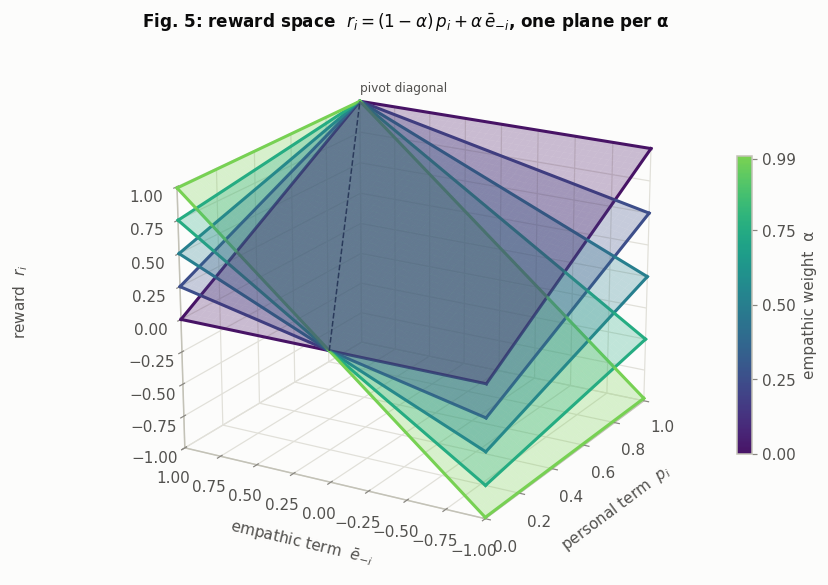

In [10]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3d projection)


class ProbeAgent:
    """agent stub carrying (p, e) directly instead of a meal history."""
    def __init__(self):
        self.p, self.e = 0.0, 0.0


class ProbeCalculator(SocialRewardCalculator):
    """shipped calculator with only the meal_history -> (p, e) mapping bypassed."""
    def calculate_homeostatic_reward(self, agent):
        return agent.p

    def calculate_emotions(self, agents):
        return [a.e for a in agents]


N_GRID = 41
p_axis = np.linspace(0, 1, N_GRID)
e_axis = np.linspace(-1, 1, N_GRID)
ZERO = N_GRID // 2     # index of e = 0 on e_axis
P, E = np.meshgrid(p_axis, e_axis, indexing="xy")
focal, others = ProbeAgent(), [ProbeAgent() for _ in range(NB_AGENTS - 1)]
R3 = {}
for a in ALPHAS:
    calc = ProbeCalculator(NB_AGENTS, alpha=a, beta=BETA, threshold=THRESHOLD,
                           smoothing=SMOOTHING, sigmoid_gain=SIGMOID_GAIN,
                           reward_scheme="homeostatic_signed")
    R = np.empty(P.shape)
    for idx in np.ndindex(P.shape):
        focal.p = P[idx]
        for o in others:
            o.e = E[idx]
        R[idx] = calc.calculate_rewards([focal] + others)[3][0]
    R3[a] = R

check("2.5 reward space", "calculator surface == (1 - alpha) p + alpha e on the whole grid",
      all(np.allclose(R3[a], (1 - a) * P + a * E, atol=1e-12) for a in ALPHAS))
check("2.5 reward space", "every plane stays inside [-alpha, 1] and passes through (0,0,0), (1,1,1)",
      all(np.isclose(R3[a].min(), -a) and np.isclose(R3[a].max(), 1) and np.isclose(R3[a][ZERO, 0], 0)
          and np.isclose(R3[a][-1, -1], 1) for a in ALPHAS))

ALPHA_CMAP = LinearSegmentedColormap.from_list(
    "alpha", plt.get_cmap("viridis")(np.linspace(0.05, 0.80, 256)))
ALPHA_NORM = Normalize(0.0, 1.0)

fig = plt.figure(figsize=(8.2, 6.4))
ax = fig.add_subplot(111, projection="3d")
for a in ALPHAS:
    col = ALPHA_CMAP(ALPHA_NORM(a))
    ax.plot_surface(P, E, R3[a], color=col, alpha=0.28, linewidth=0, shade=False)
    # plane edges, so each plane's tilt reads without relying on the translucent fill
    for row, e_val in ((0, -1.0), (-1, 1.0)):       # edges at e = -1 and e = 1
        ax.plot(p_axis, np.full(N_GRID, e_val), R3[a][row, :], color=col, lw=2)
    for col_i, p_val in ((0, 0.0), (-1, 1.0)):      # edges at p = 0 and p = 1
        ax.plot(np.full(N_GRID, p_val), e_axis, R3[a][:, col_i], color=col, lw=2)
ax.plot([0, 1], [0, 1], [0, 1], color=INK["primary"], lw=1, ls="--")
ax.text(1, 1, 1.08, "pivot diagonal", color=INK["secondary"], fontsize=8)
ax.set_xlabel("personal term  $p_i$", labelpad=8)
ax.set_ylabel(r"empathic term  $\bar e_{-i}$", labelpad=8)
# 2D text rather than set_zlabel: the inline 'tight' crop leaves 3D axis labels out
fig.text(0.0, 0.5, "reward  $r_i$", rotation=90, va="center", ha="right",
         color=INK["secondary"])
ax.set_xlim(0, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)
ax.set_box_aspect((1, 1, 0.8))
ax.view_init(elev=20, azim=-150)
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.set_pane_color((1, 1, 1, 0))
    axis._axinfo["grid"]["color"] = INK["grid"]
sm = ScalarMappable(cmap=ALPHA_CMAP, norm=ALPHA_NORM)
sm.set_array([])
cb = fig.colorbar(sm, ax=ax, shrink=0.55, pad=0.08, ticks=ALPHAS)
cb.set_label("empathic weight  α")
cb.outline.set_edgecolor(INK["baseline"])
ax.set_title(r"Fig. 5: reward space  $r_i = (1-\alpha)\,p_i + \alpha\,\bar e_{-i}$, "
             "one plane per α", loc="left")
plt.show()

### 2.6 The environment's own rewards, recomputed by hand

The checks above call the calculator directly. Here the **environment** runs (built by
`main_gt_ais.init_env`, random actions, several episodes), and every reward it returns
is recomputed from scratch with an independent re-implementation (own meal windows
rebuilt from `info['immediate_rewards']`, emotion map written out). This also checks the
Markov property the design relies on: the own-meals slot observed at $t-1$ equals the
satiety $h(t^-)$ the reward at $t$ is computed from.

In [11]:
def emotion_by_hand(rate, t=THRESHOLD):
    assert SMOOTHING == "linear"
    return (rate - t) / (1 - t) if rate >= t else -(t - rate) / t


max_err, min_r, max_r, markov_err, n_checked = 0.0, np.inf, -np.inf, 0.0, 0
for alpha in (0.5, 0.99):
    set_global_seed(SEED)
    env, agents = init_env(make_condition("check", see_emotions=True, alpha=alpha))
    assert env.social_calculator.reward_scheme == REWARD_SCHEME
    for episode in range(3):
        obs = env.reset()
        win = [deque([0.5] * MEMORY_SIZE, maxlen=MEMORY_SIZE) for _ in agents]
        for step in range(400):
            acts = [int(np.random.rand() < 0.6) for _ in agents]
            prev_obs = obs
            obs, rewards, done, info = env.step(acts)
            h_before = [sum(w) / MEMORY_SIZE for w in win]
            for i, m in enumerate(info["immediate_rewards"]):
                win[i].append(int(m))
            emo = [emotion_by_hand(sum(w) / MEMORY_SIZE) for w in win]
            for i in range(NB_AGENTS):
                m = info["immediate_rewards"][i]
                p = m * (1 - h_before[i])
                if REWARD_SCHEME == "homeostatic_signed":
                    e = np.mean([emo[j] for j in range(NB_AGENTS) if j != i])
                else:
                    e = (np.mean([emo[j] for j in range(NB_AGENTS) if j != i]) + 1) / 2
                r = (1 - alpha) * p + alpha * e
                max_err = max(max_err, abs(r - rewards[i]))
                markov_err = max(markov_err, abs(prev_obs[i][1] - h_before[i]))
                min_r, max_r = min(min_r, rewards[i]), max(max_r, rewards[i])
                n_checked += 1
            if done:
                break

print(f"{n_checked:,} agent-steps checked, rewards in [{min_r:.3f}, {max_r:.3f}]")
check("2.6 env", f"env rewards == hand-computed {REWARD_SCHEME} rewards (|err| < 1e-12)",
      max_err < 1e-12)
check("2.6 env", "env rewards stay in [-alpha, 1]", min_r >= -0.99 and max_r <= 1)
check("2.6 env", "own-meals slot at t-1 == satiety h(t-) used by the reward at t (Markov)",
      markov_err < 1e-12)

14,400 agent-steps checked, rewards in [-0.990, 0.580]
PASS  env rewards == hand-computed homeostatic_signed rewards (|err| < 1e-12)
PASS  env rewards stay in [-alpha, 1]
PASS  own-meals slot at t-1 == satiety h(t-) used by the reward at t (Markov)


## 3. Observation

The observed social signal is on the **same scale** as the empathic term of the scheme ($[-1,1]$ for
`homeostatic_signed`). The agent observes **each** other agent's emotion, in one slot per neighbour
and in a fixed order (`EMOTION_TYPE = "vector"`). The binary `see_emotions` is a shortcut for a
precision $\rho\in[0,1]$. For a true value $x$ written on the unit scale, the observation is a Beta
draw with its **mode at the true value** (concentration $\kappa = 2\rho/(1-\rho)$), then rescaled
to the emotion scale:

$$\hat x\sim\mathrm{Beta}\bigl(1+\kappa x,\;1+\kappa(1-x)\bigr).$$

$\rho=0$ gives $\mathrm{Beta}(1,1)$, uniform whatever the truth; $\rho\to1$ gives a Dirac at $x$
(implemented exactly at $\rho=1$).

### 3.1 The distribution family

For a true value $x$, the observation density at a few precisions: analytic Beta
density (line) against 200 000 draws from the shipped `perceive_bounded` (histogram).
Sections 3.1 and 3.2 work on the unit scale, where the law is written (`OBS_RANGE`). Section 3.3
checks the environment's observations on the scale of the journal model. Two truths: one in the
middle, one near the edge, to show the support never leaves the scale and the mode stays on the
truth.

Useful closed form: $E[\hat x\mid x] = \frac{1+\kappa x}{2+\kappa} = \rho\,x + (1-\rho)\tfrac12$:
the mean observation is the truth shrunk toward the neutral emotion by
exactly $\rho$, while the **mode** stays on $x$.

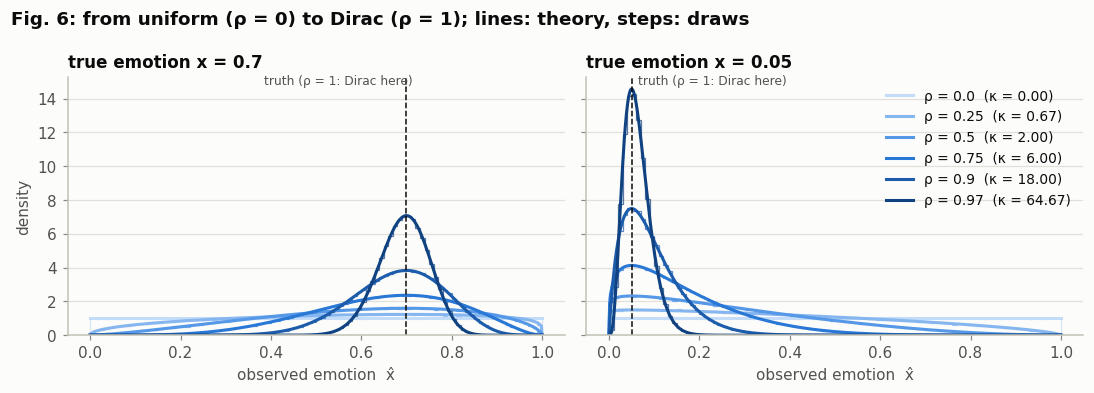

PASS  perceive_bounded draws follow the stated Beta law (KS p > 0.001, all ρ, x)
PASS  observations never leave [0, 1]
PASS  density mode sits on the true value for every ρ > 0
PASS  ρ = 0: uniform on [0, 1] (KS p > 0.001)
PASS  ρ = 1: returns the true value exactly


In [12]:
RHOS = [0.0, 0.25, 0.5, 0.75, 0.9, 0.97]
OBS_RANGE = (0.0, 1.0)   # unit scale of the Beta law, section 3.3 checks the env's own scale
LO, HI = OBS_RANGE
TRUTHS = [0.7, 0.05]
N_DRAWS = 200_000
xx = np.linspace(LO, HI, 801)

np.random.seed(SEED)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
ks_ok, support_ok, mode_ok = True, True, True
for ax, x in zip(axes, TRUTHS):
    for rho, col in zip(RHOS, ORDINAL_BLUE):
        k = precision_to_concentration(rho)
        a, b = 1 + k * x, 1 + k * (1 - x)
        draws = perceive_bounded(np.full(N_DRAWS, x), rho, low=LO, high=HI)
        support_ok &= bool((draws >= LO).all() and (draws <= HI).all())
        ks_ok &= stats.kstest(draws, stats.beta(a, b).cdf).pvalue > 0.001
        dens = stats.beta(a, b).pdf(xx)
        if rho > 0:
            mode_ok &= abs(xx[np.argmax(dens)] - x) <= 2 * (xx[1] - xx[0])
        ax.hist(draws, bins=100, range=(LO, HI), density=True, histtype="step",
                color=col, lw=0.8, alpha=0.7)
        ax.plot(xx, dens, color=col, lw=2, label=f"ρ = {rho}  (κ = {k:.2f})")
    ax.axvline(x, color=INK["primary"], lw=1, ls="--")
    ax.annotate("truth (ρ = 1: Dirac here)", (x, 0.97), xycoords=("data", "axes fraction"),
                xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK["secondary"],
                ha="left" if x < 0.5 else "right")
    ax.set_title(f"true emotion x = {x}")
    ax.set_xlabel("observed emotion  x̂")
axes[0].set_ylabel("density")
axes[1].legend(loc="upper right")
fig.suptitle("Fig. 6: from uniform (ρ = 0) to Dirac (ρ = 1); lines: theory, steps: draws",
             x=0.01, ha="left", fontweight="semibold")
fig.tight_layout()
plt.show()

check("3.1 family", "perceive_bounded draws follow the stated Beta law (KS p > 0.001, all ρ, x)",
      ks_ok)
check("3.1 family", "observations never leave [0, 1]", support_ok)
check("3.1 family", "density mode sits on the true value for every ρ > 0", mode_ok)

d0 = perceive_bounded(np.full(N_DRAWS, 0.7), 0.0, low=LO, high=HI)
check("3.1 family", "ρ = 0: uniform on [0, 1] (KS p > 0.001)",
      stats.kstest(d0, stats.uniform(LO, HI - LO).cdf).pvalue > 0.001)
exact = np.array([0., .3, 1.])
check("3.1 family", "ρ = 1: returns the true value exactly",
      perceive_bounded(0.7, 1.0, low=LO, high=HI) == 0.7
      and np.array_equal(perceive_bounded(exact, 1.0, low=LO, high=HI), exact))

### 3.2 How much the observation tells, as a function of ρ

Truth drawn uniformly on $[0,1]$, one observation each (200 000 pairs per ρ).
(a) mean observation given the truth, with ±1 sd; (b) correlation truth–observation;
(c) RMSE. The knob is continuous and monotone from "nothing" to "everything".

rho,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
corr,0.002,0.107,0.212,0.329,0.444,0.563,0.669,0.775,0.865,0.942,1.0
rmse,0.408,0.380,0.352,0.321,0.291,0.257,0.224,0.187,0.146,0.097,0.0
slope,0.002,0.103,0.200,0.301,0.401,0.503,0.597,0.700,0.801,0.900,1.0
intercept,0.499,0.449,0.400,0.349,0.299,0.248,0.201,0.150,0.100,0.050,-0.0


PASS  ρ = 0: observation uncorrelated with truth (|corr| < 0.01)
PASS  ρ = 1: perfect observation (corr = 1, RMSE = 0)
PASS  correlation strictly increasing and RMSE strictly decreasing in ρ
PASS  E[x̂ | x] = ρ x + (1 - ρ)/2  (slope and intercept, |err| < 0.01)


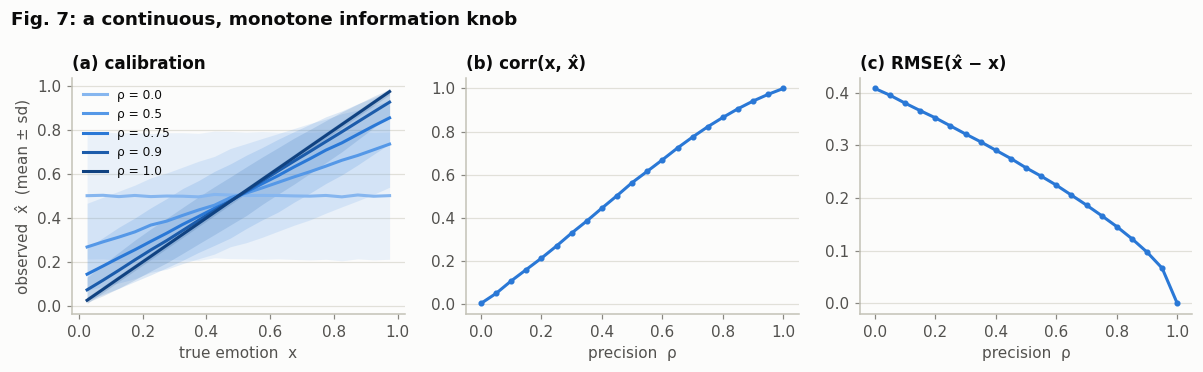

In [13]:
np.random.seed(SEED + 1)
rho_grid = np.round(np.linspace(0, 1, 21), 2)
truth = np.random.uniform(LO, HI, N_DRAWS)
info_rows = []
for rho in rho_grid:
    obs_ = perceive_bounded(truth, rho, low=LO, high=HI)
    slope, intercept = np.polyfit(truth, obs_, 1)
    info_rows.append((rho, np.corrcoef(truth, obs_)[0, 1],
                      np.sqrt(np.mean((obs_ - truth) ** 2)), slope, intercept))
info_df = pd.DataFrame(info_rows, columns=["rho", "corr", "rmse", "slope",
                                           "intercept"]).set_index("rho")
display(info_df.iloc[::2].round(3).T)

check("3.2 information", "ρ = 0: observation uncorrelated with truth (|corr| < 0.01)",
      abs(info_df.loc[0.0, "corr"]) < 0.01)
check("3.2 information", "ρ = 1: perfect observation (corr = 1, RMSE = 0)",
      np.isclose(info_df.loc[1.0, "corr"], 1) and info_df.loc[1.0, "rmse"] == 0)
check("3.2 information", "correlation strictly increasing and RMSE strictly decreasing in ρ",
      (np.diff(info_df["corr"]) > 0).all() and (np.diff(info_df["rmse"]) < 0).all())
check("3.2 information", "E[x̂ | x] = ρ x + (1 - ρ)/2  (slope and intercept, |err| < 0.01)",
      np.abs(info_df["slope"] - info_df.index).max() < 0.01
      and np.abs(info_df["intercept"] - (1 - info_df.index) / 2).max() < 0.01)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
bins = np.linspace(LO, HI, 21)
centers = (bins[:-1] + bins[1:]) / 2
idx = np.digitize(truth, bins) - 1
for rho, col in zip([0.0, 0.5, 0.75, 0.9, 1.0], ORDINAL_BLUE[1:]):
    obs_ = perceive_bounded(truth, rho, low=LO, high=HI)
    mu = np.array([obs_[idx == b].mean() for b in range(20)])
    sd = np.array([obs_[idx == b].std() for b in range(20)])
    axes[0].fill_between(centers, mu - sd, mu + sd, color=col, alpha=0.15, lw=0)
    axes[0].plot(centers, mu, color=col, label=f"ρ = {rho}")
axes[0].set_xlabel("true emotion  x")
axes[0].set_ylabel("observed  x̂  (mean ± sd)")
axes[0].set_title("(a) calibration")
axes[0].legend(loc="upper left", fontsize=8)
axes[1].plot(info_df.index, info_df["corr"], color=ORDINAL_BLUE[3], marker="o", ms=3)
axes[1].set_xlabel("precision  ρ")
axes[1].set_title("(b) corr(x, x̂)")
axes[2].plot(info_df.index, info_df["rmse"], color=ORDINAL_BLUE[3], marker="o", ms=3)
axes[2].set_xlabel("precision  ρ")
axes[2].set_title("(c) RMSE(x̂ − x)")
fig.suptitle("Fig. 7: a continuous, monotone information knob", x=0.01, ha="left",
             fontweight="semibold")
fig.tight_layout()
plt.show()

### 3.3 The environment's own observations

Now through `GameTheoreticEnv.get_observations()`, with populations built by
`main_gt_ais.init_env` / `make_condition` and, for the heterogeneous case, explicit
per-agent `agent_configs`. The truth each agent should see is recomputed from the
environment's own emotion calculator at the same instant (rounded like the env does)
and put on the scheme's emotion scale ($[-1,1]$ for `homeostatic_signed`): in `"vector"` mode each slot must equal the emotion of
the neighbour it stands for (whose mean is the empathic term of the agent's reward); in
`"average"` mode the single slot must equal that empathic term.

In [14]:
def true_social(env, i):
    """true value(s) behind agent i's social slot(s), on the scheme's emotion scale:
    the mean of the others ('average') or each other agent in index order ('vector')."""
    emo = np.round(env.social_calculator.calculate_emotions(env.agents), EMOTION_DECIMALS)
    others = np.array([e for j, e in enumerate(emo) if j != i], dtype=float)
    if env.emotion_type == "average":
        others = np.array([others.mean()])
    return env.social_calculator.rescale_emotion(others)


def collect(env, n_steps=3000, p_eat=0.5):
    """(agent, observed social slot, true value) over random play, one row per slot."""
    out = []
    obs = env.reset()
    for _ in range(n_steps):
        for i in range(NB_AGENTS):
            for o_k, t_k in zip(obs[i][2:2 + env._social_slot_size()], true_social(env, i)):
                out.append((i, o_k, t_k))
        obs, _, done, _ = env.step([int(np.random.rand() < p_eat) for _ in range(NB_AGENTS)])
        if done:
            obs = env.reset()
    return pd.DataFrame(out, columns=["agent", "obs", "truth"])


sizes, per_rho = {}, {}
for rho in [0.0, 0.5, 0.9, 1.0]:
    set_global_seed(SEED)
    env, _ = init_env(make_condition("check", see_emotions=True, alpha=0.5,
                                     emotion_precision=rho))
    sizes[rho] = env.state_size
    per_rho[rho] = collect(env)
    print(f"ρ = {rho}: state_size = {env.state_size}, "
          f"corr(truth, obs) = {per_rho[rho][['obs', 'truth']].corr().iloc[0, 1]:.3f}")

check("3.3 env", "observation dimension identical at every ρ", len(set(sizes.values())) == 1)
check("3.3 env", "ρ = 1: each env social slot == the emotion it stands for, on the scheme's scale",
      np.allclose(per_rho[1.0].obs, per_rho[1.0].truth, atol=1e-12))
d = per_rho[0.0]
# slots are rounded to EMOTION_DECIMALS: test against the ROUNDED uniform law
# (grid of step 0.01 on the emotion scale, half-mass end points) with a chi-square. a KS test
# against the continuous uniform rejects on the rounding grid alone once there
# are N-1 slots per agent (90 000 values in vector mode).
grid = 10 ** EMOTION_DECIMALS
low, high = env.social_calculator.emotion_range
cells = int(round((high - low) * grid))
counts = np.bincount(np.round((d.obs.values - low) * grid).astype(int), minlength=cells + 1)
p_round = np.full(cells + 1, 1.0 / cells)
p_round[[0, -1]] = 0.5 / cells
check("3.3 env", "ρ = 0: env social slots uniform on the emotion scale (χ² vs rounded uniform, p > 0.001) and uncorrelated",
      stats.chisquare(counts, len(d) * p_round).pvalue > 0.001
      and abs(d[["obs", "truth"]].corr().iloc[0, 1]) < 0.05)

# see_emotions=False is a shortcut for ρ = 0 (uniform noise)
set_global_seed(SEED)
env_blind, _ = init_env(make_condition("blind", see_emotions=False, alpha=0.5))
blind = collect(env_blind, n_steps=1000)
check("3.3 env", "see_emotions=False -> ρ = 0 for every agent, slot is uniform noise",
      all(a.get_emotion_precision() == 0.0 for a in env_blind.agents)
      and abs(blind.obs.std() - (high - low) * np.sqrt(1 / 12)) < 0.02)

# exact observation draws nothing from the RNG: rho = 1 runs keep the random stream
set_global_seed(SEED)
env1, _ = init_env(make_condition("check", see_emotions=True, alpha=0.5))
env1.reset()
state_before = np.random.get_state()[1].copy(), np.random.get_state()[2]
env1.get_observations()
state_after = np.random.get_state()[1], np.random.get_state()[2]
check("3.3 env", "ρ = 1: get_observations() consumes no random draws",
      np.array_equal(state_before[0], state_after[0]) and state_before[1] == state_after[1])

ρ = 0.0: state_size = 7, corr(truth, obs) = -0.002


ρ = 0.5: state_size = 7, corr(truth, obs) = 0.338


ρ = 0.9: state_size = 7, corr(truth, obs) = 0.892


ρ = 1.0: state_size = 7, corr(truth, obs) = 1.000
PASS  observation dimension identical at every ρ
PASS  ρ = 1: each env social slot == the emotion it stands for, on the scheme's scale
PASS  ρ = 0: env social slots uniform on the emotion scale (χ² vs rounded uniform, p > 0.001) and uncorrelated


PASS  see_emotions=False -> ρ = 0 for every agent, slot is uniform noise
PASS  ρ = 1: get_observations() consumes no random draws


In [15]:
# heterogeneous population: one precision per agent, set through agent_configs
from agent_policies_gt_ais import DQNAgent

het_rhos = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
set_global_seed(SEED)
env_het = GameTheoreticEnv(
    nb_agents=NB_AGENTS, initial_resources=500, env_type="stochastic", alpha=0.5,
    agent_class=DQNAgent, threshold=THRESHOLD, smoothing=SMOOTHING,
    round_emotions=EMOTION_DECIMALS,
    agent_configs=[{"see_emotions": True, "emotion_precision": r} for r in het_rhos])
het = collect(env_het)
het_corr = het.groupby("agent")[["obs", "truth"]].apply(lambda g: g.corr().iloc[0, 1])
display(pd.DataFrame({"ρ": het_rhos, "corr(truth, obs)": het_corr.round(3).values}).T)

check("3.3 env", "per-agent ρ is honoured: precisions read back from the agents",
      [a.get_emotion_precision() for a in env_het.agents] == het_rhos)
check("3.3 env", "per-agent ρ is honoured: corr(truth, obs) increases with each agent's ρ",
      (np.diff(het_corr.values) > 0).all())

# vector social channel: one independent noisy draw per other agent
set_global_seed(SEED)
env_vec = GameTheoreticEnv(nb_agents=NB_AGENTS, emotion_type="vector", alpha=0.5,
                           agent_class=DQNAgent, emotion_precision=0.5,
                           round_emotions=EMOTION_DECIMALS)
o = env_vec.reset()
check("3.3 env", "vector mode: N-1 social slots, all inside the emotion scale",
      env_vec.state_size == 2 + NB_AGENTS - 1
      and all(((x[2:] >= low) & (x[2:] <= high)).all() for x in o))

,0,1,2,3,4,5
ρ,0.000,0.200,0.40,0.600,0.800,1.0
"corr(truth, obs)",0.002,0.105,0.25,0.437,0.732,1.0


PASS  per-agent ρ is honoured: precisions read back from the agents
PASS  per-agent ρ is honoured: corr(truth, obs) increases with each agent's ρ
PASS  vector mode: N-1 social slots, all inside the emotion scale


## 4. Check summary

In [16]:
summary = pd.DataFrame(CHECKS, columns=["section", "check", "passed"])
pd.set_option("display.max_colwidth", 120)
display(summary)
n_fail = (~summary.passed).sum()
print(f"{len(summary) - n_fail}/{len(summary)} checks passed")
assert n_fail == 0, "some checks failed, see the table above"

,section,check,passed
0,2.1 bounds,"signed: personal term spans [0, 1], empathic term spans [-1, 1]",True
1,2.1 bounds,"signed: reward attains exactly [-alpha, 1] at EVERY alpha",True
2,2.1 bounds,"signed: empathic term == mean others' emotion, the scale of the observation",True
3,2.1 bounds,"homeostatic: personal and empathic terms both span exactly [0, 1]",True
4,2.1 bounds,"homeostatic: reward attains exactly [0, 1] at EVERY alpha",True
5,2.1 bounds,homeostatic: no negative reward anywhere,True
6,2.1 bounds,"homeostatic: empathic term == (mean others' emotion + 1) / 2, the scale of the observation",True
7,2.1 bounds,"legacy: reward interval is [-alpha, 1]",True
8,2.1 bounds,"total = (1 - alpha) * personal + alpha * empathic, all schemes",True
9,2.2 orientation,signed: value of a meal = 1 - satiety before it (exact),True


38/38 checks passed


## 5. Modelling notes

1. **Scale of the reward.** The journal model is `homeostatic_signed`: the empathic term and the
   observation are on $[-1,1]$, so the others' distress is a penalty, and $r_i\in[-\alpha_i,1]$. The
   reward is negative when the others are starving, and the episode stops at depletion with no
   terminal penalty: whether depletion can raise the return should be checked. The `homeostatic`
   scheme, on $[0,1]$, avoids the question.
2. **Homeostatic set-point is implicit.** With $p = m(1-h)$ the steady-state optimum
   is $f = 0.5$ (Fig. 3), which happens to equal `THRESHOLD = 0.5` (the neutral emotion).
   A different set-point $h^\*$ would need another functional form.
3. **The emotion is monotone in consumption.** Each agent's *own* reward peaks at
   $f = 0.5$, but its broadcast emotion (and hence the empathic term of its neighbours)
   keeps increasing up to $f = 1$. An empathic agent therefore "wants" the others to
   eat more than they themselves would want. Making the emotion homeostatic too (e.g.
   emotion ∝ own personal reward) would make the model coherent.
4. **`see_emotions=False` is uniform noise** on the emotion scale, not a constant 0 as in the AIS
   runs. Both carry zero information, but the network input has variance, so conditions labelled
   "blind" in 03_GT are not bit-identical to the AIS ones.
5. **Only the social slot is noisy.** `perceive_bounded` is generic (any bounded
   quantity), so the resource slot could get the same treatment.
6. **ρ shrinks the mean, not the mode** ($E[\hat x\mid x] = \rho x + (1-\rho)/2$ on the unit
   scale). With `emotion_type='vector'` (the 03_GT default) each neighbour's emotion
   gets its own independent draw, so every slot is exactly uniform at $\rho = 0$. Note:
   an agent that averages its $N-1$ noisy slots recovers the mean emotion with *less*
   noise than one draw of the mean (`'average'` mode) at the same ρ, so ρ values are not
   comparable across the two modes.
7. **Empathic term of the reward vs emotion observation.** Both are on the scale of the scheme
   (checked in 2.1 and 3.3). The empathic reward uses the *true* value while the agent only
   perceives $\hat x$. Rewarding the agent on what it perceives would make ρ act on both observation
   and motivation, but would change the meaning of condition B ("blind but empathic reward"), which
   exists only because the two are decoupled.